# Does the running back tip off a pass?

Many offenses split carries between two running backs. If one back mostly plays on passing downs, a defense can read the play from **which back is on the field**.

**Method**
1. Use nflverse **participation data** to find which RBs were on the field for each play. Fullbacks are excluded.
2. For each team, take the two backs with the most snaps (RB1 and RB2). Compare plays where **only RB1** was on the field with plays where **only RB2** was.
3. Raw pass rate is misleading, because backups often play 3rd downs and 2-minute drills. So we also use **`xpass`**, nflverse's expected chance of a pass given down, distance, field position, score and time.
4. **Pass rate over expected (PROE)** = actual pass rate − average `xpass`. The gap between the two backs' PROE is the tell.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays, load_participation, rb_pass_tendencies
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

SEASON = 2025
plays = offensive_plays(load_pbp(SEASON))  # regular season, pass + run, win prob. 10-90%
participation = load_participation(SEASON)

## How often are two RBs on the field together?
Rarely. Teams "use two backs" mostly by **rotating** them, so we compare each back on the field alone.

In [2]:
from nfl_analytics.rb_tendencies import rb_on_field

rbs = rb_on_field(plays, participation)
rbs.groupby(["game_id", "play_id"]).size().value_counts().rename_axis("RBs on field").to_frame("plays")

,plays
RBs on field,
1,25588
2,749
3,2


## RB1 vs. RB2 tendencies
Only teams where each back was alone on the field for at least 144 plays (8 per week).

In [3]:
stats = rb_pass_tendencies(plays, participation, min_plays=144)
stats[["rb1_name", "rb2_name", "rb1_plays", "rb2_plays",
       "rb1_pass_rate", "rb2_pass_rate", "rb1_proe", "rb2_proe", "proe_gap", "significant"]]

,rb1_name,rb2_name,rb1_plays,rb2_plays,rb1_pass_rate,rb2_pass_rate,rb1_proe,rb2_proe,proe_gap,significant
team,,,,,,,,,,
BAL,D. Henry,J. Hill,455,151,0.385,0.801,-0.147,0.027,1.739e-01,True
CLE,Q. Judkins,J. Ford,382,187,0.419,0.904,-0.107,0.053,1.593e-01,True
KC,K. Hunt,I. Pacheco,450,335,0.667,0.684,0.009,0.108,9.865e-02,True
HOU,W. Marks,N. Chubb,474,291,0.601,0.591,-0.032,0.059,9.121e-02,True
PIT,J. Warren,K. Gainwell,418,399,0.495,0.759,-0.054,0.033,8.679e-02,True
BUF,J. Cook,T. Johnson,506,234,0.466,0.803,-0.066,0.018,8.380e-02,True
NYJ,B. Hall,I. Davis,459,170,0.495,0.753,-0.106,-0.054,5.253e-02,False
NE,T. Henderson,R. Stevenson,360,355,0.586,0.690,0.003,0.054,5.125e-02,False
DET,J. Gibbs,D. Montgomery,520,256,0.596,0.582,-0.072,-0.028,4.390e-02,False


## Raw pass rate vs. pass rate over expected
The raw gap is much larger than the PROE gap. Most of the difference comes from **when** each back plays, not **who** he is.

In [4]:
compare = pd.DataFrame({
    "raw_gap": stats["rb2_pass_rate"] - stats["rb1_pass_rate"],
    "expected_gap": stats["rb2_xpass"] - stats["rb1_xpass"],
    "proe_gap": stats["proe_gap"],
})
print("Average across committee teams (percentage points):")
print((compare.mean() * 100).round(1).to_string())
print(f"\nTeams with a significant tell: {stats['significant'].sum()} of {len(stats)} "
      f"(about {0.05 * len(stats):.1f} expected by chance)")

Average across committee teams (percentage points):
raw_gap         9.0
expected_gap    5.8
proe_gap        3.3

Teams with a significant tell: 7 of 25 (about 1.2 expected by chance)


## The chart

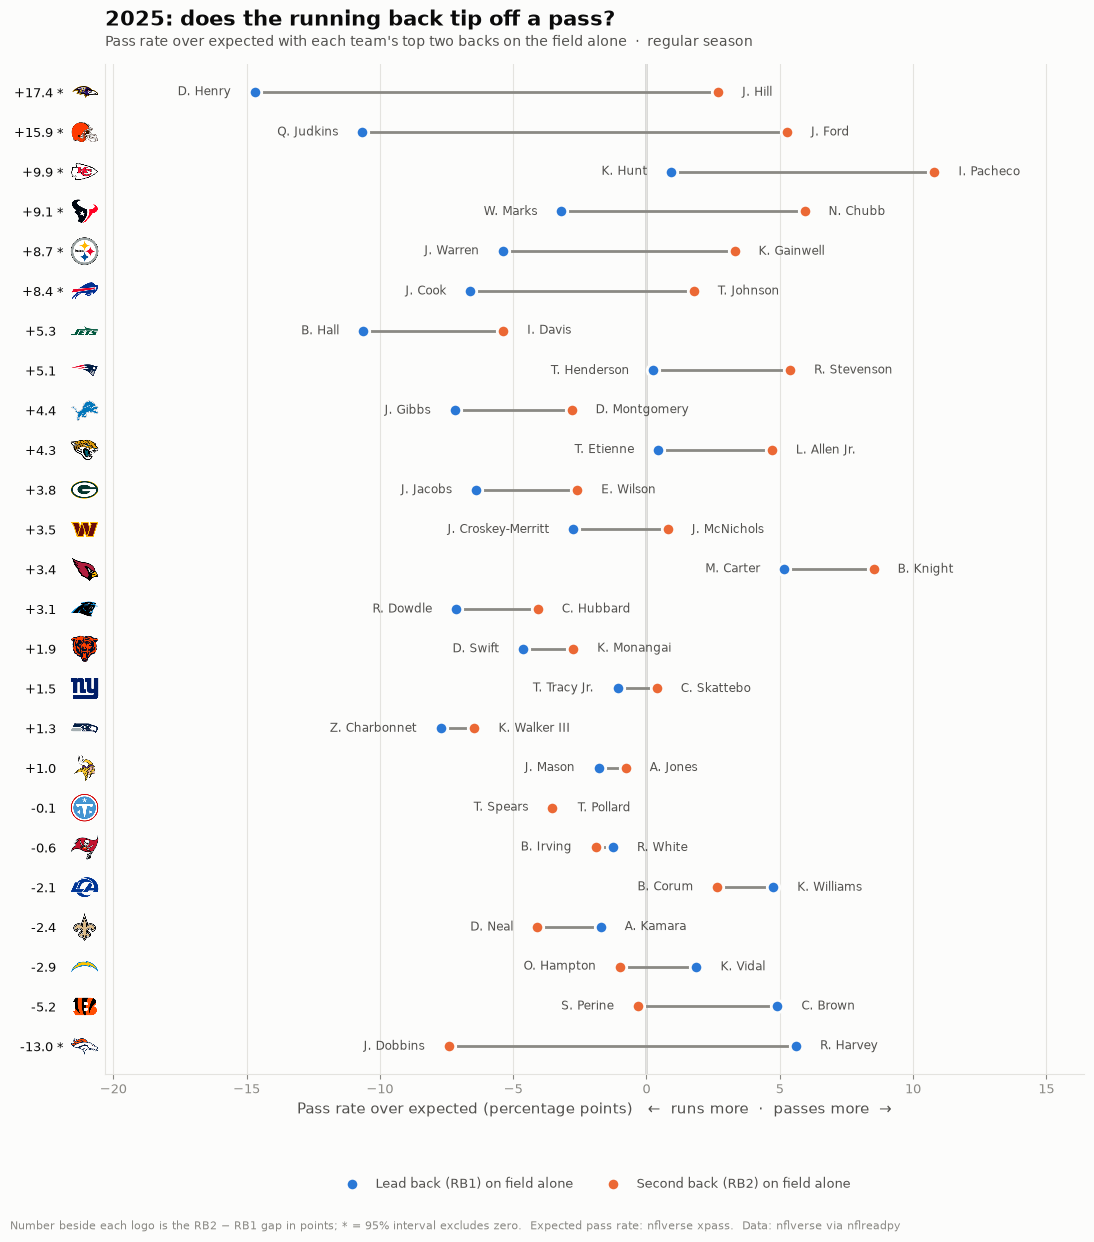

In [5]:
from nfl_analytics import plot_rb_tendencies

fig, ax = plot_rb_tendencies(
    stats,
    title=f"{SEASON}: does the running back tip off a pass?",
    subtitle="Pass rate over expected with each team's top two backs on the field alone  ·  regular season",
)

## Caveats
- **`xpass` doesn't capture everything.** Personnel and formation (e.g., an empty backfield) also signal a pass, so some of the gap may come from the formation the back plays in, not the back himself.
- **Injuries and depth-chart changes** mean RB2's plays may cluster in certain weeks or opponents.
- **Multiple comparisons:** with ~25 teams, about 1 will look significant by chance alone at the 95% level.

## Ideas to explore next
- Does the tell **cost** anything? Compare EPA per play for RB2's runs vs. his passes. If defenses read it, his runs should struggle.
- Split by **down** to find exactly where each back's usage diverges.
- Track it **week by week**. Did any team become less predictable during the season?
- Use `offense_formation` to separate the back's effect from the formation's.